# Phân loại ảnh CIFAR-100 bằng PyTorch

Notebook này huấn luyện một mạng CNN để phân loại ảnh vào 100 lớp CIFAR-100. Dữ liệu được tải tự động qua `torchvision`. Nếu máy có GPU NVIDIA và cài bản PyTorch hỗ trợ CUDA, notebook sẽ tự chọn GPU.

In [16]:
# N?u thi?u th? vi?n, b? d?u # v? ch?y cell n?y, sau ?? kh?i ??ng l?i kernel.
# %pip install torch torchvision matplotlib scikit-learn

import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
import matplotlib.pyplot as plt
import matplotlib as mpl

# Cấu hình Matplotlib sử dụng font hỗ trợ tiếng Việt trên Windows/macOS/Linux
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'Times New Roman', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False  # Tránh lỗi hiển thị dấu trừ (-)

PyTorch: 2.14.0+cpu
Device: cpu


## Tải và chia dữ liệu CIFAR-100

Tập huấn luyện ban đầu có 50.000 ảnh, được chia thành 45.000 ảnh train và 5.000 ảnh validation. Tập test có 10.000 ảnh. Chỉ tập train dùng crop và lật ngang ngẫu nhiên; validation và test chỉ được chuẩn hóa.

In [17]:
DATA_DIR = './data'
BATCH_SIZE = 128

mean = (0.5071, 0.4867, 0.4408)
std = (0.2675, 0.2565, 0.2761)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# T?i b? d? li?u l?n ??u c?n k?t n?i Internet.
train_augmented = datasets.CIFAR100(DATA_DIR, train=True, download=True, transform=train_transform)
train_unaugmented = datasets.CIFAR100(DATA_DIR, train=True, download=False, transform=eval_transform)
test_dataset = datasets.CIFAR100(DATA_DIR, train=False, download=True, transform=eval_transform)
class_names = train_augmented.classes

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_augmented), generator=generator).tolist()
train_indices, val_indices = indices[5000:], indices[:5000]
train_dataset = Subset(train_augmented, train_indices)
val_dataset = Subset(train_unaugmented, val_indices)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
print(f'Train: {len(train_dataset)}, validation: {len(val_dataset)}, test: {len(test_dataset)}')
print('Số lớp:', len(class_names))

Train: 45000, validation: 5000, test: 10000
Số lớp: 100


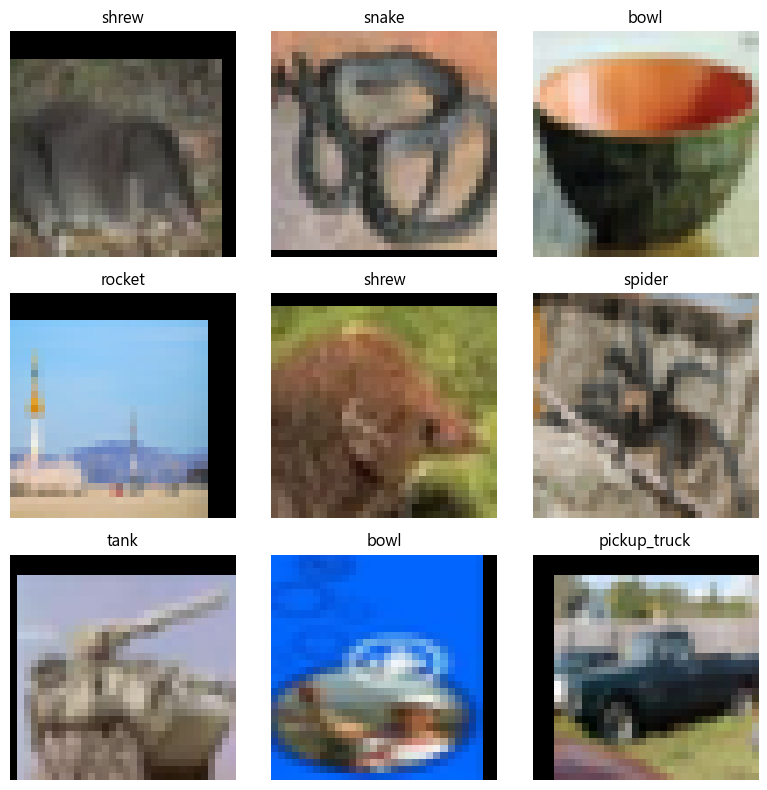

In [18]:
# Hiển thị ảnh mẫu sau khi hoàn nguyên bước chuẩn hóa.
def show_tensor_image(image):
    image = image.cpu().permute(1, 2, 0).numpy()
    image = np.clip(image * np.array(std) + np.array(mean), 0, 1)
    return image

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(show_tensor_image(images[i]))
    ax.set_title(class_names[labels[i].item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

## CNN tự xây dựng

Mô hình gồm ba khối tích chập với lần lượt 96, 192 và 384 kênh. Mỗi khối có hai lớp convolution, BatchNorm, ReLU, MaxPool và Dropout; phần phân loại xuất logits cho 100 lớp.


In [19]:

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dropout):
        super().__init__()
        self.block = nn.Sequential(
            # Convolution 1: kernel 7x7
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=7, padding=3, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            # Convolution 2: kernel 7x7
            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=7, padding=3, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(dropout),
        )

    def forward(self, x):
        return self.block(x)


class CustomCNN(nn.Module):
    def __init__(self, num_classes=100):
        super().__init__()

        self.features = nn.Sequential(
            ConvBlock(3, 96, dropout=0.10),
            ConvBlock(96, 192, dropout=0.15),
            ConvBlock(192, 384, dropout=0.20),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(384, 384),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(384, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Khoi tao lai mo hinh voi kernel 7x7
model = CustomCNN(num_classes=100).to(device)

print(model)
print(
    'Trainable parameters:',
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)


CustomCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), bias=False)
        (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), bias=False)
        (4): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Dropout2d(p=0.1, inplace=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(96, 192, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), bias=False)
        (1): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(192, 192, kernel_siz

## Huấn luyện mô hình

`CrossEntropyLoss` nhận logits trực tiếp nên lớp cuối không dùng Softmax. Notebook lưu checkpoint có validation loss thấp nhất và dừng sớm nếu validation loss không cải thiện trong 10 epoch liên tiếp.

In [5]:
EPOCHS = 80
PATIENCE = 10
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=3,
    min_lr=1e-5,
)

history = {'train_loss': [], 'train_accuracy': [], 'val_loss': [], 'val_accuracy': []}
best_val_loss = float('inf')
epochs_without_improvement = 0
model_path = 'cnn_cifar100_kernel7x7.pth'

for epoch in range(EPOCHS):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(inputs)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * inputs.size(0)
        train_correct += (logits.argmax(dim=1) == targets).sum().item()
        train_total += targets.size(0)

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            logits = model(inputs)
            loss = criterion(logits, targets)
            val_loss_sum += loss.item() * inputs.size(0)
            val_correct += (logits.argmax(dim=1) == targets).sum().item()
            val_total += targets.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total
    val_loss = val_loss_sum / val_total
    scheduler.step(val_loss)
    val_accuracy = val_correct / val_total
    history['train_loss'].append(train_loss)
    history['train_accuracy'].append(train_accuracy)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_accuracy)
    print(f'Epoch {epoch + 1:02d}/{EPOCHS} | train loss {train_loss:.4f}, acc {train_accuracy:.3%} | val loss {val_loss:.4f}, acc {val_accuracy:.3%}')

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), model_path)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print('Early stopping.')
            break

model.load_state_dict(torch.load(model_path, map_location=device))
print('Loaded best checkpoint:', model_path)

Epoch 01/80 | train loss 4.1104, acc 6.140% | val loss 3.8332, acc 9.180%
Epoch 02/80 | train loss 3.7946, acc 10.129% | val loss 3.5458, acc 13.260%
Epoch 03/80 | train loss 3.5569, acc 14.178% | val loss 3.3875, acc 17.340%
Epoch 04/80 | train loss 3.3136, acc 18.447% | val loss 2.9621, acc 24.200%
Epoch 05/80 | train loss 3.1194, acc 21.833% | val loss 2.8308, acc 27.200%
Epoch 06/80 | train loss 2.9442, acc 25.202% | val loss 2.6576, acc 30.500%
Epoch 07/80 | train loss 2.8047, acc 28.122% | val loss 2.5131, acc 33.660%
Epoch 08/80 | train loss 2.6646, acc 31.013% | val loss 2.3848, acc 37.040%
Epoch 09/80 | train loss 2.5447, acc 33.191% | val loss 2.2422, acc 39.380%
Epoch 10/80 | train loss 2.4264, acc 35.722% | val loss 2.3029, acc 38.220%
Epoch 11/80 | train loss 2.3392, acc 37.702% | val loss 2.0810, acc 43.380%
Epoch 12/80 | train loss 2.2366, acc 40.424% | val loss 2.0207, acc 44.540%
Epoch 13/80 | train loss 2.1551, acc 41.716% | val loss 1.9323, acc 47.320%
Epoch 14/80 | 

## BỔ SUNG PHẦN VISUALIZE

In [20]:
import os
import torch

# Kiểm tra thư mục làm việc hiện tại
print("Thư mục hiện tại:", os.getcwd())
print("File tồn tại:", os.path.exists("cnn_cifar100_kernel7x7.pth"))

Thư mục hiện tại: f:\HK9_DeepLearning\fruit_ripness_classification_using_CNN-main
File tồn tại: True


In [21]:
import torch

model = CustomCNN(num_classes=100).to(device)

checkpoint_path = "cnn_cifar100_kernel7x7.pth"
checkpoint = torch.load(checkpoint_path, map_location=device)

if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    model.load_state_dict(checkpoint["state_dict"])
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()
print("Đã khôi phục mô hình thành công!")

Đã khôi phục mô hình thành công!


## PCA - TRUC QUAN HOA DAC TRUNG CNN KERNEL 3x3

Kich thuoc ma tran dac trung: (10000, 384)
Kich thuoc nhan: (10000,)
So anh dung cho PCA: 3000
Phuong sai PC1: 9.14%
Phuong sai PC2: 5.96%
Tong phuong sai giu lai: 15.10%


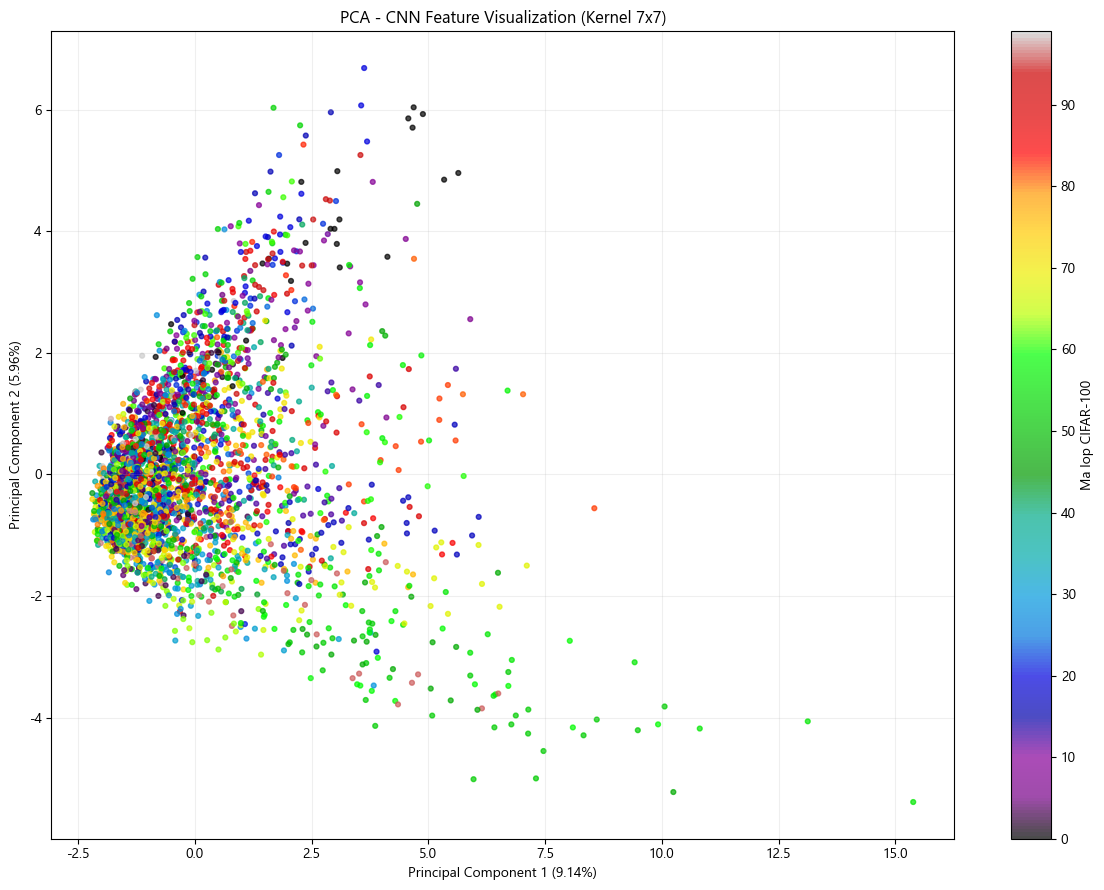

In [22]:

# ============================================================
# CELL: PCA - Giam chieu dac trung CNN tu 384D xuong 2D
# Dataset: CIFAR-100
# Model: CustomCNN voi kernel 7x7
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch

from torch.utils.data import DataLoader
from sklearn.decomposition import PCA

# ----------------------------
# 1. Cau hinh
# ----------------------------
MAX_SAMPLES = 3000   # So anh toi da dung de ve PCA
BATCH_SIZE = 128
RANDOM_STATE = 42

model.eval()

# Dung test_dataset da duoc tao o cac cell truoc
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ----------------------------
# 2. Trich xuat dac trung CNN
# ----------------------------
features_list = []
labels_list = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        # Di qua cac lop convolution
        x = model.features(images)

        # AdaptiveAvgPool2d: (B, 384, 1, 1)
        x = model.classifier[0](x)

        # Flatten: (B, 384)
        x = torch.flatten(x, start_dim=1)

        features_list.append(x.cpu().numpy())
        labels_list.append(labels.numpy())

X = np.concatenate(features_list, axis=0)
y = np.concatenate(labels_list, axis=0)

print("Kich thuoc ma tran dac trung:", X.shape)
print("Kich thuoc nhan:", y.shape)

# ----------------------------
# 3. Chon ngau nhien toi da MAX_SAMPLES anh
# ----------------------------
if len(y) > MAX_SAMPLES:
    rng = np.random.default_rng(RANDOM_STATE)
    selected_indices = rng.choice(
        len(y),
        size=MAX_SAMPLES,
        replace=False
    )

    X = X[selected_indices]
    y = y[selected_indices]

print("So anh dung cho PCA:", len(y))

# ----------------------------
# 4. PCA: 384 chieu -> 2 chieu
# ----------------------------
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

explained_variance = pca.explained_variance_ratio_

print(f"Phuong sai PC1: {explained_variance[0] * 100:.2f}%")
print(f"Phuong sai PC2: {explained_variance[1] * 100:.2f}%")
print(
    "Tong phuong sai giu lai: "
    f"{explained_variance.sum() * 100:.2f}%"
)

# ----------------------------
# 5. Ve bieu do PCA
# ----------------------------
plt.figure(figsize=(12, 9))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="nipy_spectral",
    s=12,
    alpha=0.7
)

cbar = plt.colorbar(scatter, ticks=range(0, 100, 10))
cbar.set_label("Ma lop CIFAR-100")

plt.xlabel(
    f"Principal Component 1 ({explained_variance[0] * 100:.2f}%)"
)
plt.ylabel(
    f"Principal Component 2 ({explained_variance[1] * 100:.2f}%)"
)
plt.title("PCA - CNN Feature Visualization (Kernel 7x7)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## t-SNE - CNN Feature Visualization (Kernel 3x3)

Kich thuoc dac trung: (10000, 384)
So mau dung cho t-SNE: 2000


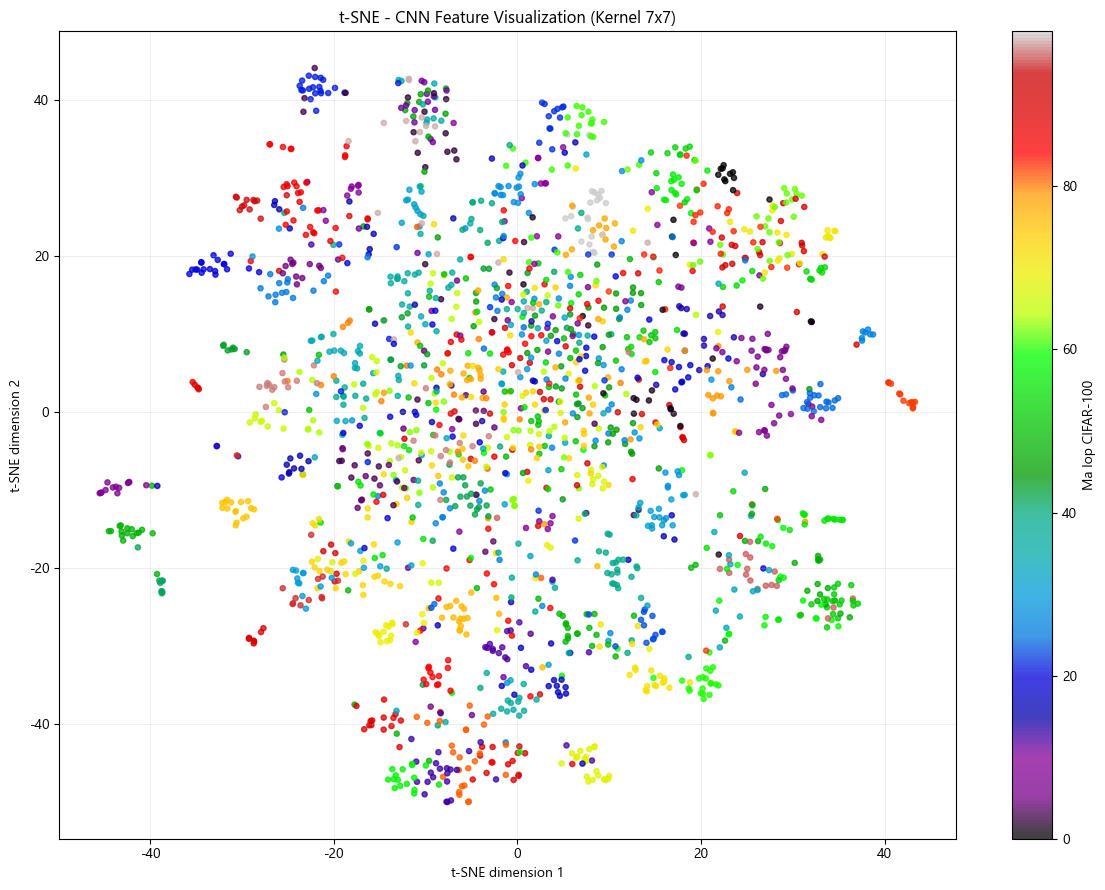

In [23]:

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. CAU HINH
# ============================================================

MAX_SAMPLES = 2000
BATCH_SIZE = 128
RANDOM_STATE = 42

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ============================================================
# 2. TRICH XUAT DAC TRUNG CNN
# ============================================================

features_list = []
labels_list = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        # Dac trung sau cac lop convolution
        x = model.features(images)

        # Global Average Pooling
        x = model.classifier[0](x)

        # (B, 384, 1, 1) -> (B, 384)
        x = torch.flatten(x, start_dim=1)

        features_list.append(x.cpu().numpy())
        labels_list.append(labels.numpy())

X = np.concatenate(features_list, axis=0)
y = np.concatenate(labels_list, axis=0)

print("Kich thuoc dac trung:", X.shape)

# ============================================================
# 3. CHON TOI DA 2000 MAU
# ============================================================

if len(y) > MAX_SAMPLES:
    rng = np.random.default_rng(RANDOM_STATE)
    indices = rng.choice(
        len(y),
        size=MAX_SAMPLES,
        replace=False
    )
    X = X[indices]
    y = y[indices]

print("So mau dung cho t-SNE:", len(y))

# ============================================================
# 4. CHUAN HOA DAC TRUNG
# ============================================================

X_scaled = StandardScaler().fit_transform(X)

# ============================================================
# 5. t-SNE: GIAM CHIEU XUONG 2D
# ============================================================

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    max_iter=1000,
    random_state=RANDOM_STATE
)

X_tsne = tsne.fit_transform(X_scaled)

# ============================================================
# 6. VE BIEU DO
# ============================================================

plt.figure(figsize=(12, 9))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y,
    cmap="nipy_spectral",
    vmin=0,
    vmax=99,
    s=14,
    alpha=0.75
)

cbar = plt.colorbar(scatter)
cbar.set_label("Ma lop CIFAR-100")

plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE - CNN Feature Visualization (Kernel 7x7)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Shape kernel: (96, 3, 7, 7)


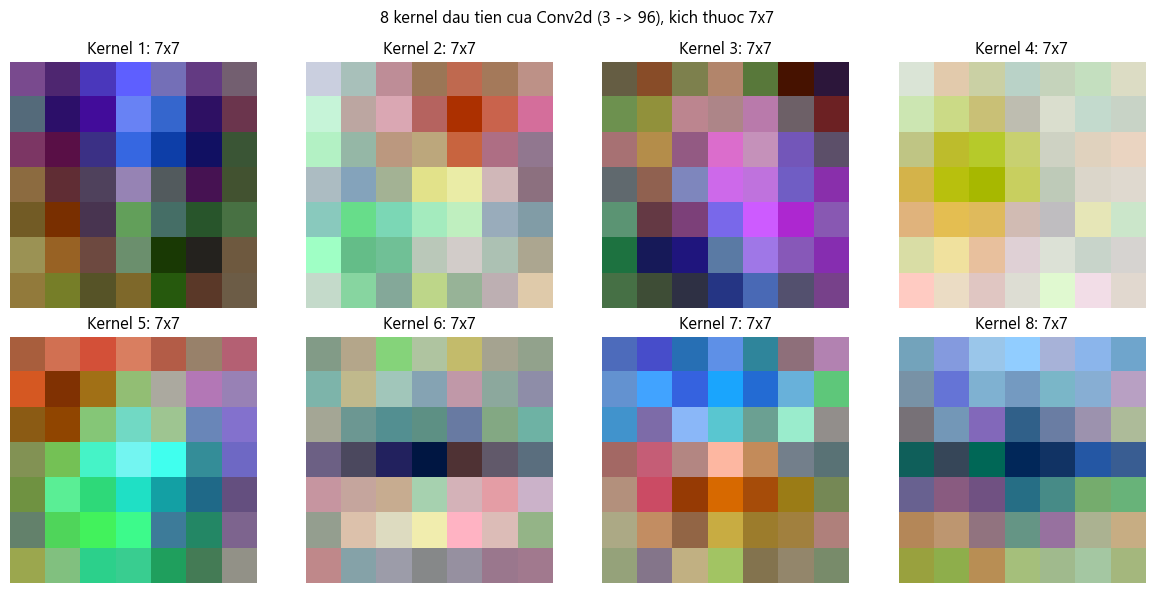

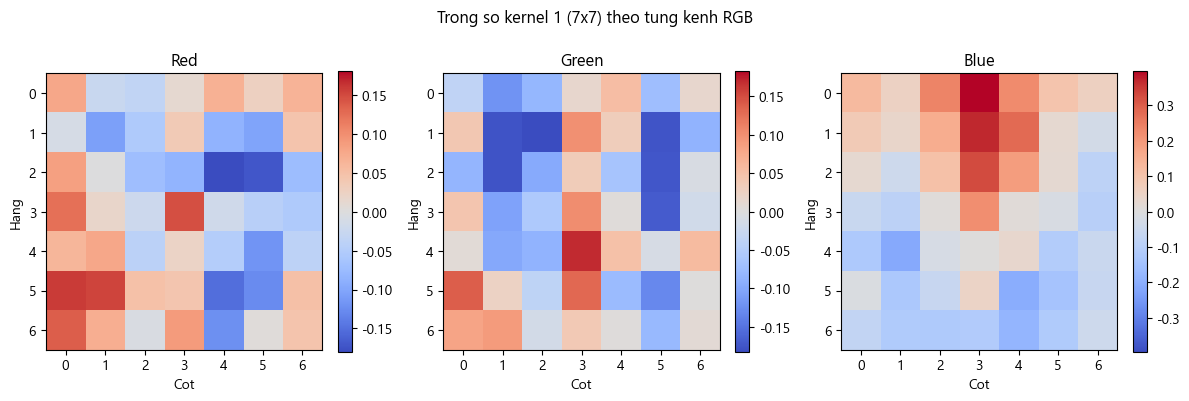

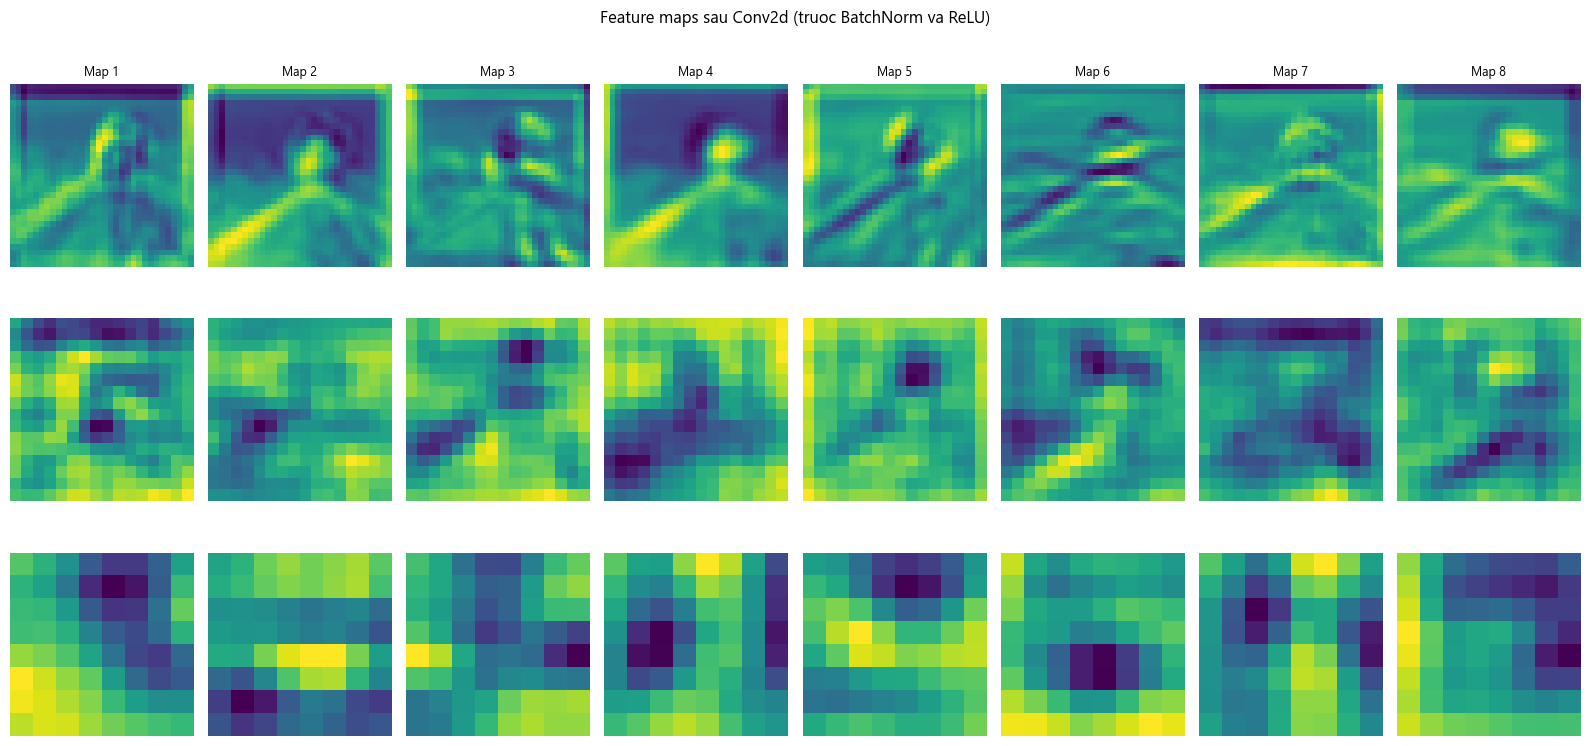

Feature vector shape: (384,)
Nhan that: mountain
Lop du doan: train


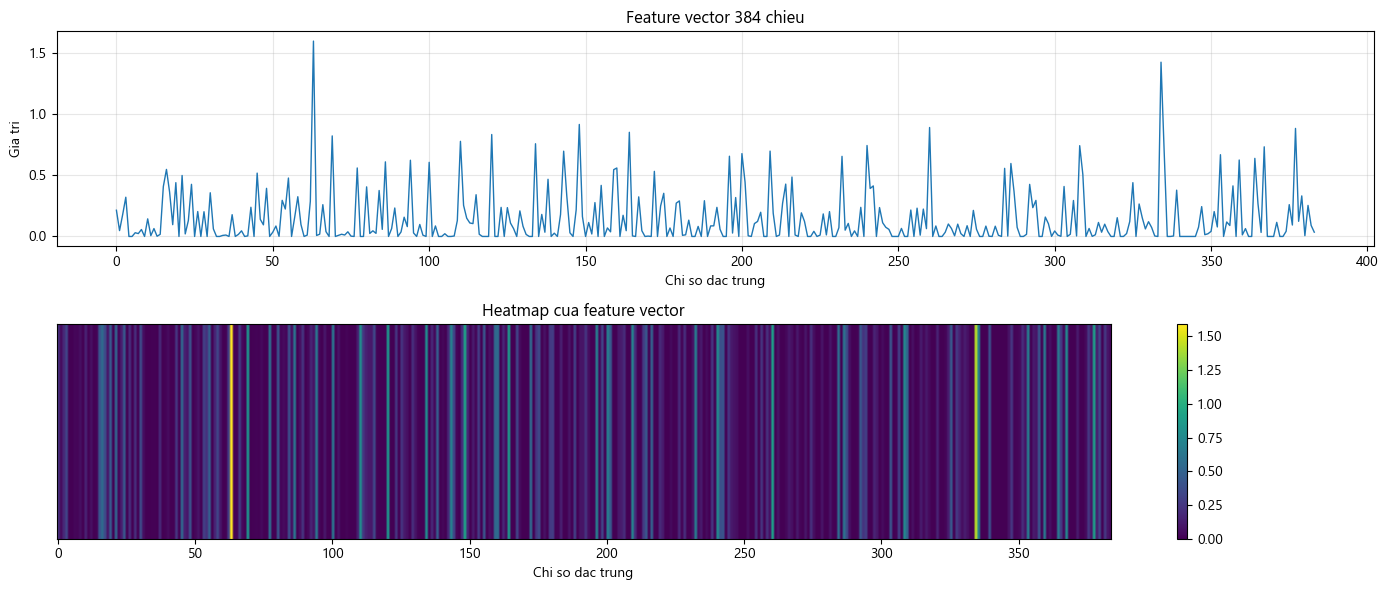

In [6]:

# ============================================================
# VISUALIZE KERNEL 7x7, FEATURE MAPS VA FEATURE VECTOR
# Yeu cau: model, device, test_dataset, class_names
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

# Chuyen mo hinh sang che do danh gia
model.eval()

# Chon mot anh tu tap test
sample_idx = 0
image_tensor, true_label = test_dataset[sample_idx]
input_batch = image_tensor.unsqueeze(0).to(device)


# ============================================================
# 1. TRUC QUAN HOA KERNEL 7x7 DA HOC
# ============================================================

# Lay lop Conv2d dau tien:
# 3 kenh RGB -> 96 kenh dau ra, kernel 7x7
conv1 = model.features[0].block[0]
weights = conv1.weight.detach().cpu()

print("Shape kernel:", tuple(weights.shape))
# Ket qua mong doi: (96, 3, 7, 7)

# Kiem tra kich thuoc kernel
assert weights.shape[2:] == (7, 7), (
    "Kernel khong phai 7x7. "
    "Hay chay lai cell dinh nghia model kernel 7x7."
)

# Hien thi 8 kernel dau tien dang RGB
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    # Shape: (3, 7, 7) -> (7, 7, 3)
    kernel = weights[i].permute(1, 2, 0).numpy()

    # Chuan hoa tung kernel de de quan sat
    k_min, k_max = kernel.min(), kernel.max()
    kernel_vis = (kernel - k_min) / (k_max - k_min + 1e-8)

    ax.imshow(kernel_vis, interpolation="nearest")
    ax.set_title(f"Kernel {i + 1}: 7x7")
    ax.axis("off")

plt.suptitle("8 kernel dau tien cua Conv2d (3 -> 96), kich thuoc 7x7")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Hien thi rieng 3 kenh R, G, B cua mot kernel
# ------------------------------------------------------------

kernel_id = 0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for c, ax in enumerate(axes):
    # Moi kenh co kich thuoc 7x7
    channel = weights[kernel_id, c].numpy()
    vmax = np.abs(channel).max() + 1e-8

    im = ax.imshow(
        channel,
        cmap="coolwarm",
        vmin=-vmax,
        vmax=vmax,
        interpolation="nearest"
    )

    ax.set_title(["Red", "Green", "Blue"][c])
    ax.set_xticks(range(7))
    ax.set_yticks(range(7))
    ax.set_xlabel("Cot")
    ax.set_ylabel("Hang")

    plt.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle(
    f"Trong so kernel {kernel_id + 1} (7x7) theo tung kenh RGB"
)
plt.tight_layout()
plt.show()


# ============================================================
# 2. TRUC QUAN HOA FEATURE MAP SAU CONVOLUTION
# ============================================================

feature_outputs = {}


def save_feature(name):
    def hook(module, inputs, output):
        feature_outputs[name] = output.detach().cpu().clone()
    return hook


# Hook vao Conv2d dau tien cua moi ConvBlock
layers = {
    "ConvBlock 1": model.features[0].block[0],
    "ConvBlock 2": model.features[1].block[0],
    "ConvBlock 3": model.features[2].block[0],
}

handles = []

for name, layer in layers.items():
    handles.append(
        layer.register_forward_hook(save_feature(name))
    )

# Forward mot lan de thu thap feature maps va logits
with torch.no_grad():
    logits = model(input_batch)

# Go tat ca hook sau khi thu thap xong
for handle in handles:
    handle.remove()


# Ve 8 feature maps dau tien cua moi lop Conv
fig, axes = plt.subplots(3, 8, figsize=(16, 8))

for row, (name, feature) in enumerate(feature_outputs.items()):
    # Shape: (C, H, W)
    fmap = feature[0]

    for col in range(8):
        ax = axes[row, col]
        ax.imshow(fmap[col].numpy(), cmap="viridis")
        ax.axis("off")

        if row == 0:
            ax.set_title(f"Map {col + 1}", fontsize=9)

    axes[row, 0].set_ylabel(
        f"{name}\n{tuple(fmap.shape)}",
        fontsize=9
    )

plt.suptitle(
    "Feature maps sau Conv2d (truoc BatchNorm va ReLU)"
)
plt.tight_layout()
plt.show()


# ============================================================
# 3. TRUC QUAN HOA FEATURE VECTOR 384 CHIEU
# ============================================================

pooled_features = {}


def save_pooled(module, inputs, output):
    pooled_features["vector"] = output.detach().cpu().clone()


# Hook vao AdaptiveAvgPool2d
handle = model.classifier[0].register_forward_hook(save_pooled)

with torch.no_grad():
    logits = model(input_batch)

handle.remove()

# Dau ra AdaptiveAvgPool2d co shape (1, 384, 1, 1)
feature_vector = pooled_features["vector"].flatten().numpy()

print("Feature vector shape:", feature_vector.shape)
print("Nhan that:", class_names[true_label])
print("Lop du doan:", class_names[logits.argmax(dim=1).item()])

# Ve feature vector va heatmap
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

# Bieu dien 384 gia tri dac trung
axes[0].plot(
    np.arange(len(feature_vector)),
    feature_vector,
    linewidth=1
)
axes[0].set_title("Feature vector 384 chieu")
axes[0].set_xlabel("Chi so dac trung")
axes[0].set_ylabel("Gia tri")
axes[0].grid(alpha=0.3)

# Heatmap cua feature vector
im = axes[1].imshow(
    feature_vector.reshape(1, -1),
    aspect="auto",
    cmap="viridis"
)

axes[1].set_title("Heatmap cua feature vector")
axes[1].set_xlabel("Chi so dac trung")
axes[1].set_yticks([])

plt.colorbar(im, ax=axes[1], orientation="vertical")

plt.tight_layout()
plt.show()


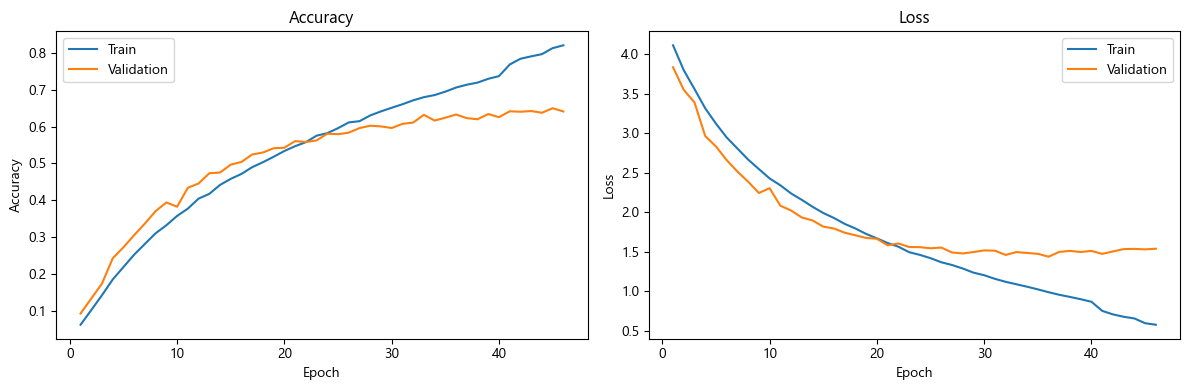

In [7]:
# Vẽ đường cong accuracy và loss
epoch_range = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epoch_range, history['train_accuracy'], label='Train')
axes[0].plot(epoch_range, history['val_accuracy'], label='Validation')
axes[0].set(title='Accuracy', xlabel='Epoch', ylabel='Accuracy')
axes[0].legend()
axes[1].plot(epoch_range, history['train_loss'], label='Train')
axes[1].plot(epoch_range, history['val_loss'], label='Validation')
axes[1].set(title='Loss', xlabel='Epoch', ylabel='Loss')
axes[1].legend()
plt.tight_layout()
plt.show()

## Đánh giá trên tập test

In [8]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for inputs, targets in test_loader:
        logits = model(inputs.to(device))
        y_pred.extend(logits.argmax(dim=1).cpu().tolist())
        y_true.extend(targets.tolist())

test_accuracy = np.mean(np.array(y_true) == np.array(y_pred))
print(f'Test accuracy: {test_accuracy:.2%}')
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

Test accuracy: 62.25%
               precision    recall  f1-score   support

        apple       0.78      0.84      0.81       100
aquarium_fish       0.78      0.75      0.77       100
         baby       0.59      0.41      0.48       100
         bear       0.40      0.27      0.32       100
       beaver       0.62      0.39      0.48       100
          bed       0.60      0.70      0.65       100
          bee       0.73      0.63      0.68       100
       beetle       0.67      0.59      0.63       100
      bicycle       0.80      0.77      0.79       100
       bottle       0.77      0.73      0.75       100
         bowl       0.41      0.52      0.46       100
          boy       0.38      0.48      0.42       100
       bridge       0.77      0.70      0.73       100
          bus       0.60      0.61      0.60       100
    butterfly       0.44      0.62      0.51       100
        camel       0.59      0.64      0.62       100
          can       0.60      0.68      0.

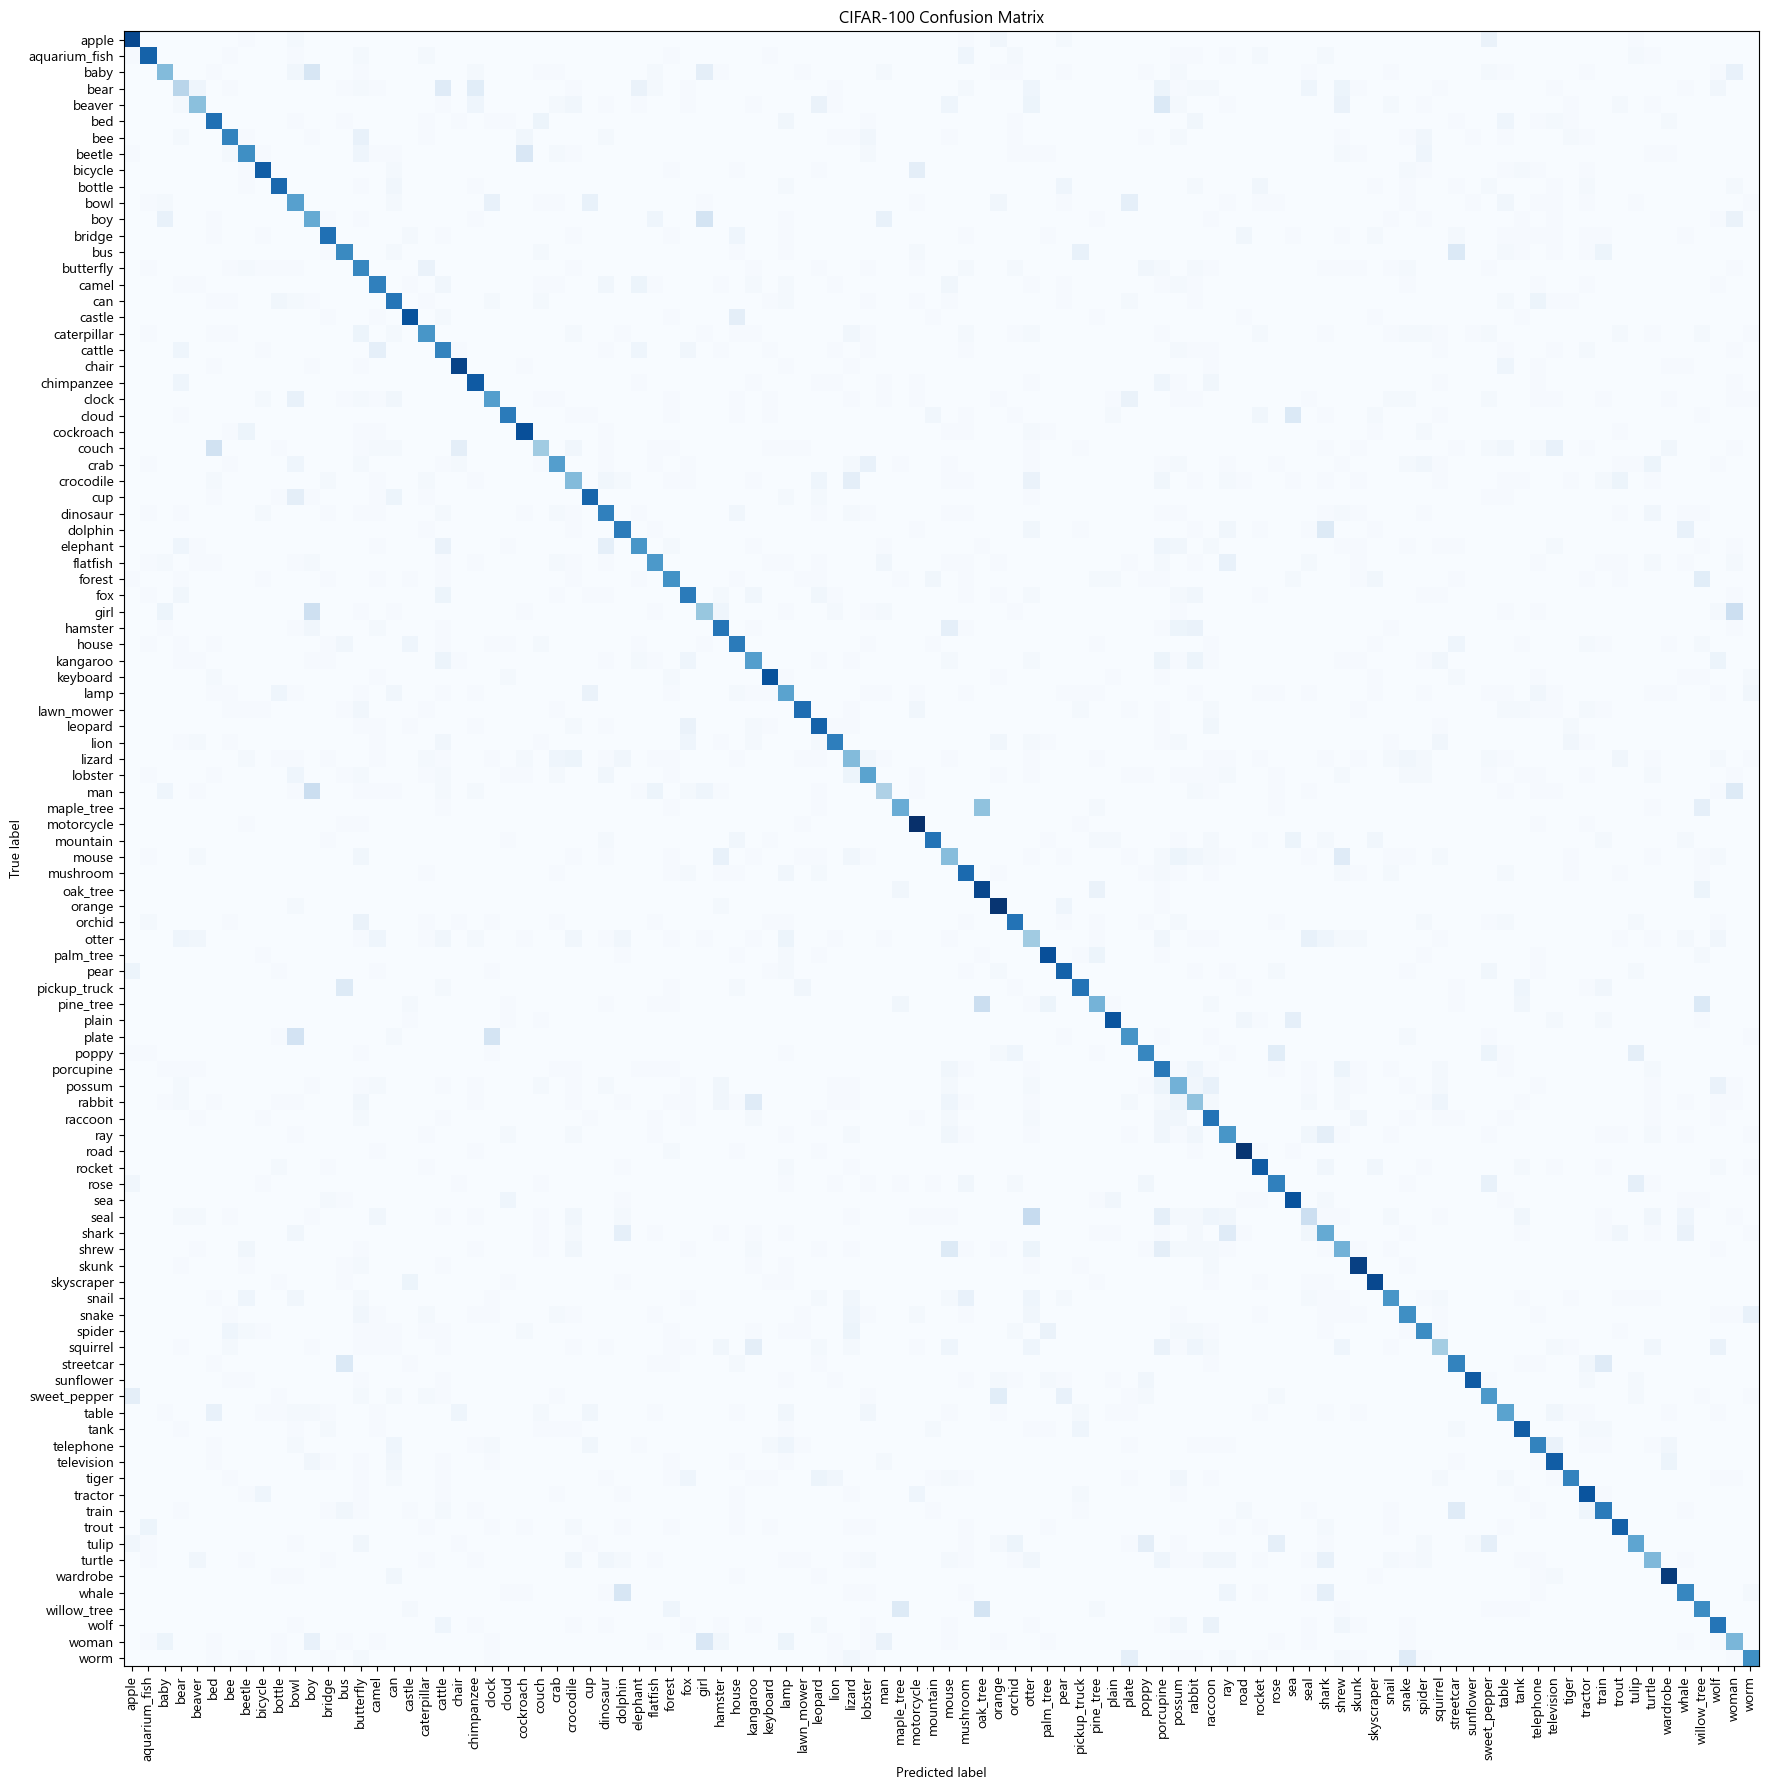

In [9]:
# Ma trận nhầm lẫn cho 100 lớp.
cm = confusion_matrix(y_true, y_pred, labels=range(100))
fig, ax = plt.subplots(figsize=(18, 18))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
display.plot(ax=ax, cmap='Blues', xticks_rotation='vertical', colorbar=False, include_values=False)
plt.title('CIFAR-100 Confusion Matrix')
plt.tight_layout()
plt.show()

In [10]:
# Lưu trọng số mô hình PyTorch (state_dict).)
torch.save(model.state_dict(), model_path)
print('Đã lưu:', model_path)

Đã lưu: cnn_cifar100_kernel7x7.pth
